<a href="https://colab.research.google.com/github/fralfaro/inf449-portafolio/blob/main/tareas/tarea-02/homework2.ipynb" target="_parent">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>


# Tarea 2: Neural Networks Driven by Physics and CNNs for RGB Demosaicking

**Fotografia Computacional**  
**Universidad Tecnica Federico Santa Maria**

En esta tarea se estudia el problema de reconstruccion de imagenes RGB a partir de mediciones con mosaico Bayer obtenidas desde sensores reales. En particular, se busca comparar metodos clasicos de demosaicking con aproximaciones basadas en redes neuronales, incluyendo representaciones neuronales implicitas y redes convolucionales.


## 1. Enunciado

El objetivo general de la tarea es reconstruir una imagen RGB a partir de una medicion mosaico capturada por un dispositivo electronico, como un telefono, tablet o camara digital. La medicion corresponde a una imagen RAW o DNG generada por un sensor cubierto con un arreglo de filtros de color Bayer.

A partir de esta medicion, se deben implementar y analizar algoritmos de demosaicking basados en:

1. Metodos tradicionales de interpolacion.
2. Representaciones neuronales implicitas.
3. Redes neuronales convolucionales.

Los resultados deben compararse cuantitativa y cualitativamente con una imagen RGB de referencia, por ejemplo la imagen procesada automaticamente por el dispositivo.


## 2. Contexto teorico

Una camara digital usualmente no mide directamente los tres canales de color en cada pixel. En su lugar, el sensor registra una unica intensidad por posicion espacial, filtrada por un patron Bayer. Para un patron Bayer tipo **RGGB**, la distribucion local de filtros puede representarse como

$$
\begin{bmatrix}
R & G \\
G & B
\end{bmatrix}.
$$

Sea

$$
I \in \mathbb{R}^{H \times W \times 3}
$$

la imagen RGB ideal, donde $H$ y $W$ son la altura y el ancho de la imagen. La medicion mosaico puede modelarse como

$$
Y(i,j) = \sum_{c \in \{R,G,B\}} M_c(i,j) I_c(i,j),
$$

donde $M_c$ es una mascara binaria que indica si el canal $c$ fue medido en la posicion $(i,j)$.

El problema de **demosaicking** consiste en estimar una imagen RGB completa

$$
\hat{I} \in \mathbb{R}^{H \times W \times 3}
$$

a partir de la medicion incompleta $Y$.


## 3. Objetivos

Los objetivos especificos de esta tarea son:

1. Obtener o utilizar una imagen RAW/DNG junto con una imagen RGB de referencia.
2. Representar la medicion del sensor como un mosaico Bayer.
3. Reconstruir la imagen RGB usando un metodo clasico de demosaicking.
4. Reconstruir la imagen RGB usando una representacion neuronal implicita.
5. Reconstruir la imagen RGB usando una red neuronal convolucional.
6. Comparar los metodos mediante metricas objetivas y observaciones visuales.
7. Analizar el efecto de modificar la arquitectura o estrategia de entrenamiento de las redes.


## 4. Preparacion del entorno

En esta seccion se cargaran las librerias necesarias para trabajar con imagenes, arreglos numericos, visualizacion, metricas y entrenamiento de redes neuronales.

Las implementaciones finales deberian considerar, al menos:

- `numpy` para operaciones numericas.
- `matplotlib` para visualizacion.
- `Pillow` u `OpenCV` para lectura y procesamiento de imagenes.
- `torch` para definir y entrenar redes neuronales.
- `pandas` para organizar los resultados experimentales.


In [1]:
# Dependencias para Google Colab
# En Colab, torch suele venir instalado. Esta celda asegura el resto de paquetes usados en la tarea.
%pip install -q opencv-python scikit-image scipy pillow pandas matplotlib rawpy imageio

# Imports generales
from pathlib import Path
from collections import OrderedDict
import os
import time
import math
import urllib.request
import zipfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image

import cv2
from skimage import data
from skimage.transform import resize
from skimage.metrics import peak_signal_noise_ratio
from skimage.metrics import structural_similarity as ssim
from scipy.ndimage import correlate

try:
    import rawpy
except ImportError:
    rawpy = None

import torch
from torch import nn, optim
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {DEVICE}")


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.0/3.0 MB 38.9 MB/s eta 0:00:00
Device: cuda


## 5. Datos de trabajo

El eje experimental de esta tarea sera una captura real compuesta por dos archivos:

1. **`demo.dng`**: medicion RAW del sensor, con una sola intensidad por pixel y metadatos del arreglo CFA/Bayer.
2. **`demo.jpg`**: imagen RGB procesada por la camara, usada como referencia visual y como aproximacion practica para comparar reconstrucciones.

A diferencia de un experimento completamente sintetico, aqui el mosaico Bayer no se genera desde una imagen RGB conocida, sino que se lee directamente desde el archivo DNG. El JPG no es una referencia lineal ideal, porque ya paso por el pipeline interno de la camara: demosaicking, balance de blancos, correccion de color, reduccion de ruido, nitidez, compresion y mapeo tonal. Por eso las metricas deben interpretarse como una comparacion aproximada contra la salida de la camara, no como una medicion absoluta de fidelidad fisica.

Los archivos originales `bursts_0006.dng`, `bursts_0006.tiff` y `bursts_0006.jpg` se mantienen solo como referencia de una captura no utilizable. En el resto del notebook, el flujo de trabajo se construye en torno a `demo.dng` y `demo.jpg`.


### Captura real RAW/DNG

En esta seccion se descarga una captura real valida en formato `DNG` junto con su referencia `JPG` procesada por la camara. El objetivo no es entrenar con esta imagen, sino verificar que el notebook puede leer una medicion RAW real, extraer informacion del arreglo CFA/Bayer desde los metadatos y visualizar cualitativamente la diferencia entre la medicion del sensor y una imagen ya procesada por el pipeline interno de la camara.

En Google Colab, las siguientes celdas descargan automaticamente los archivos desde GitHub.


In [2]:
from pathlib import Path
import urllib.request

DATA_DIR = Path("data/raw_demo")
DATA_DIR.mkdir(parents=True, exist_ok=True)

RAW_URL = "https://raw.githubusercontent.com/fralfaro/images/refs/heads/main/demo.dng"
JPG_URL = "https://raw.githubusercontent.com/fralfaro/images/refs/heads/main/demo.jpg"
RAW_PATH = DATA_DIR / "demo.dng"
JPG_PATH = DATA_DIR / "demo.jpg"

for url, out_path in [(RAW_URL, RAW_PATH), (JPG_URL, JPG_PATH)]:
    if not out_path.exists():
        urllib.request.urlretrieve(url, out_path)
    print(f"{out_path}: {out_path.stat().st_size / 1024**2:.2f} MB")


data/raw_demo/demo.dng: 7.99 MB
data/raw_demo/demo.jpg: 1.89 MB


In [3]:
# rawpy permite leer DNG/RAW y hacer un revelado basico.
# En Colab normalmente basta con instalarlo una vez por sesion.
try:
    import rawpy
except ImportError:
    import subprocess
    import sys
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "rawpy"])
    import rawpy


In [4]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
import rawpy

with rawpy.imread(str(RAW_PATH)) as raw:
    raw_visible = raw.raw_image_visible.astype(np.float32).copy()
    black = np.array(raw.black_level_per_channel, dtype=np.float32)
    white = float(raw.white_level)
    color_desc = raw.color_desc.decode("ascii")
    raw_pattern = raw.raw_pattern.copy()
    rgb_from_raw = raw.postprocess(
        use_camera_wb=True,
        no_auto_bright=True,
        output_bps=8,
    )

jpg_ref = np.asarray(ImageOps.exif_transpose(Image.open(JPG_PATH)).convert("RGB"))

pattern_letters = np.array(list(color_desc))[raw_pattern]
bayer_pattern = "".join(pattern_letters.ravel())

print("Forma RAW visible:", raw_visible.shape)
print("Forma JPG referencia:", jpg_ref.shape)
print("Descripcion de colores CFA:", color_desc)
print("Patron Bayer/CFA detectado:")
print(pattern_letters)
print("Patron 2x2:", bayer_pattern)
print("Black levels por canal:", black.astype(int).tolist())
print("White level:", int(white))

black_floor = float(np.min(black))
white_display = white
if white_display <= black_floor:
    # Algunos DNG de telefono reportan niveles no lineales; para visualizar y entrenar,
    # se usa un rango robusto basado en percentiles de la medicion visible.
    black_floor, white_display = np.percentile(raw_visible, [1, 99.8])

raw_mosaic_full = raw_visible.copy()
raw_mosaic_full = np.maximum(raw_mosaic_full - black_floor, 0)
raw_mosaic_full = raw_mosaic_full / max(white_display - black_floor, 1)
raw_mosaic_full = np.clip(raw_mosaic_full, 0, 1).astype(np.float32)


Forma RAW visible: (3060, 4080)
Forma JPG referencia: (4080, 3060, 3)
Descripcion de colores CFA: RGBG
Patron Bayer/CFA detectado:
[['G' 'R']
 ['B' 'G']]
Patron 2x2: GRBG
Black levels por canal: [63, 63, 63, 63]
White level: 1023


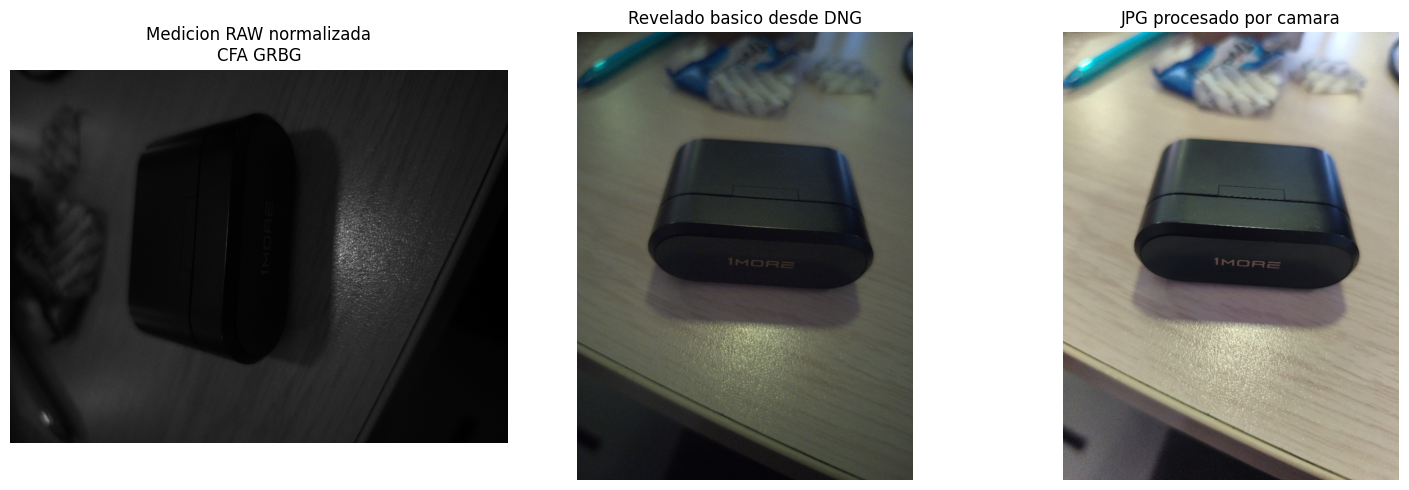

In [5]:
raw_norm = raw_mosaic_full

# Se usa una version reducida para que la visualizacion sea liviana en Colab.
max_side = 1200
scale_raw = max(raw_norm.shape) / max_side
scale_jpg = max(jpg_ref.shape[:2]) / max_side
step_raw = max(1, int(np.ceil(scale_raw)))
step_jpg = max(1, int(np.ceil(scale_jpg)))

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(raw_norm[::step_raw, ::step_raw], cmap="gray")
axes[0].set_title(f"Medicion RAW normalizada\nCFA {bayer_pattern}")
axes[0].axis("off")

axes[1].imshow(rgb_from_raw[::step_raw, ::step_raw])
axes[1].set_title("Revelado basico desde DNG")
axes[1].axis("off")

axes[2].imshow(jpg_ref[::step_jpg, ::step_jpg])
axes[2].set_title("JPG procesado por camara")
axes[2].axis("off")

plt.tight_layout()
plt.show()


La captura `demo.dng` corresponde a una medicion real del sensor: contiene una sola intensidad por posicion espacial y los metadatos permiten recuperar el arreglo CFA/Bayer usado por la camara. En cambio, `demo.jpg` ya incluye el procesamiento interno del dispositivo, incluyendo demosaicking, balance de blancos, correccion de color, reduccion de ruido, nitidez, compresion y posiblemente mapeo tonal.

Por eso la comparacion visual no debe interpretarse como una metrica objetiva de demosaicking: el JPG no es una referencia lineal pura del sensor, sino una version procesada para visualizacion. Aun asi, esta seccion completa la validacion cualitativa con una captura RAW/DNG real y muestra como conectar el experimento sintetico con datos capturados por una camara.


## 6. Preparacion de la captura real

Para que el entrenamiento sea liviano en Colab, se trabaja con un recorte cuadrado de la captura real. La variable `mosaic` se obtiene desde la medicion RAW del DNG y `rgb_reference` se obtiene desde el JPG procesado por la camara.

Esto cambia la interpretacion del experimento:

- El dato de entrada fisico es el mosaico real del sensor.
- La referencia RGB es la salida procesada por la camara, no una verdad de terreno perfecta.
- Las metricas MSE, PSNR y SSIM se usan como indicadores comparativos respecto al JPG, mientras que la inspeccion visual sigue siendo fundamental.


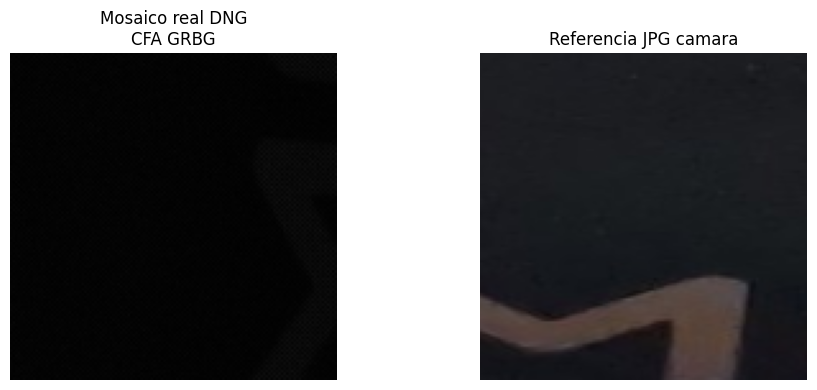

In [6]:
# Preparacion de recorte real DNG/JPG
def bayer_masks(height, width, pattern="RGGB"):
    patterns = {
        "RGGB": np.array([[0, 1], [1, 2]]),
        "BGGR": np.array([[2, 1], [1, 0]]),
        "GRBG": np.array([[1, 0], [2, 1]]),
        "GBRG": np.array([[1, 2], [0, 1]]),
    }
    if pattern not in patterns:
        raise ValueError(f"Patron Bayer no soportado: {pattern}")
    tile = patterns[pattern]
    masks = np.zeros((height, width, 3), dtype=np.float32)
    for row in range(2):
        for col in range(2):
            masks[row::2, col::2, tile[row, col]] = 1.0
    return masks

N = 128

jpg_float_full = jpg_ref.astype(np.float32) / 255.0
if jpg_float_full.shape[:2] != raw_mosaic_full.shape:
    jpg_float_full = resize(
        jpg_float_full,
        raw_mosaic_full.shape,
        anti_aliasing=True,
        preserve_range=True,
    ).astype(np.float32)

def center_crop_pair(raw_image, rgb_image, size):
    height, width = raw_image.shape[:2]
    top = (height - size) // 2
    left = (width - size) // 2
    raw_crop = raw_image[top:top + size, left:left + size]
    rgb_crop = rgb_image[top:top + size, left:left + size]
    return raw_crop.astype(np.float32), np.clip(rgb_crop.astype(np.float32), 0.0, 1.0)

mosaic, rgb_reference = center_crop_pair(raw_mosaic_full, jpg_float_full, N)
bayer = bayer_masks(N, N, pattern=bayer_pattern)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].imshow(mosaic, cmap="gray", vmin=0, vmax=1)
axes[0].set_title(f"Mosaico real DNG\nCFA {bayer_pattern}")
axes[1].imshow(rgb_reference)
axes[1].set_title("Referencia JPG camara")
for ax in axes:
    ax.axis("off")
plt.tight_layout()


## 7. Modelo de mosaico Bayer real

Para un patron Bayer detectado desde el DNG, se definen tres mascaras binarias:

$$
M_R, M_G, M_B \in \{0,1\}^{H \times W}.
$$

Cada mascara indica las posiciones del sensor donde se mide cada canal. En una imagen sintetica se podria construir

$$
Y = M_R \odot I_R + M_G \odot I_G + M_B \odot I_B,
$$

pero en esta version el mosaico $Y$ ya viene dado por `demo.dng`. Las mascaras se usan para indicar a los modelos que canal fue observado en cada posicion.


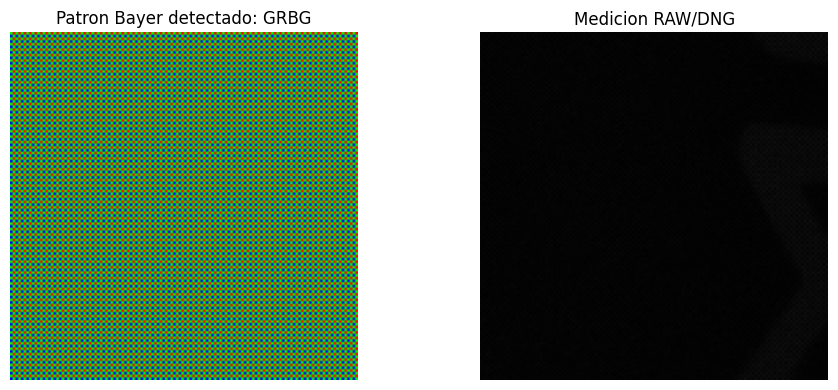

In [7]:
# Mascaras Bayer y utilidades de mosaico
def bayer_masks(height, width, pattern="RGGB"):
    """Construye mascaras binarias RGB para un patron Bayer de 2x2."""
    patterns = {
        "RGGB": np.array([[0, 1], [1, 2]]),
        "BGGR": np.array([[2, 1], [1, 0]]),
        "GRBG": np.array([[1, 0], [2, 1]]),
        "GBRG": np.array([[1, 2], [0, 1]]),
    }
    if pattern not in patterns:
        raise ValueError(f"Patron Bayer no soportado: {pattern}")
    tile = patterns[pattern]
    masks = np.zeros((height, width, 3), dtype=np.float32)
    for row in range(2):
        for col in range(2):
            masks[row::2, col::2, tile[row, col]] = 1.0
    return masks

def make_bayer_mosaic(rgb_image, masks):
    """Genera un mosaico sintetico; se usa solo para entrenar con datasets RGB auxiliares."""
    return np.sum(rgb_image * masks, axis=-1).astype(np.float32)

# Si esta celda se ejecuta despues de la preparacion, solo visualiza el patron real ya detectado.
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].imshow(bayer)
axes[0].set_title(f"Patron Bayer detectado: {bayer_pattern}")
axes[1].imshow(mosaic, cmap="gray", vmin=0, vmax=1)
axes[1].set_title("Medicion RAW/DNG")
for ax in axes:
    ax.axis("off")
plt.tight_layout()


## 8. Metodo clasico de demosaicking

Como linea base, se debe reconstruir la imagen RGB usando un metodo tradicional. Un enfoque simple consiste en interpolar los valores faltantes de cada canal a partir de las muestras disponibles.

La reconstruccion clasica se denotara como

$$
\hat{I}_{\text{clasico}}.
$$

Esta reconstruccion servira como referencia inicial para evaluar si los metodos neuronales entregan mejoras cuantitativas o visuales.


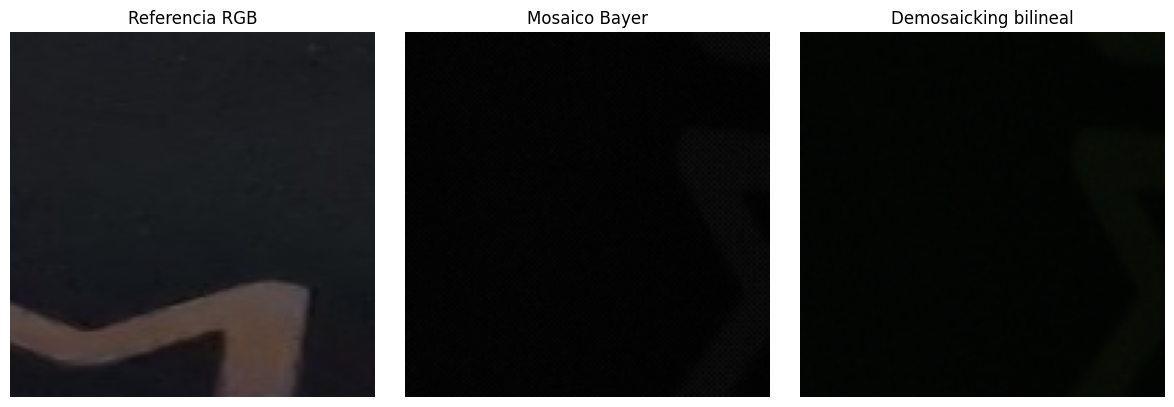

In [8]:
# Demosaicking clasico por interpolacion bilineal
def demosaic_bilinear(mosaic, masks):
    # Los kernels separables estiman los valores faltantes de cada canal.
    kernels = [
        np.array([[1, 2, 1], [2, 4, 2], [1, 2, 1]], dtype=np.float32),
        np.array([[0, 1, 0], [1, 4, 1], [0, 1, 0]], dtype=np.float32),
        np.array([[1, 2, 1], [2, 4, 2], [1, 2, 1]], dtype=np.float32),
    ]
    channels = []
    for channel, kernel in enumerate(kernels):
        observed = mosaic * masks[..., channel]
        estimate = correlate(observed, kernel, mode="mirror") / 4.0
        # Conserva exactamente las muestras que el sensor si observo.
        channels.append(np.where(masks[..., channel] > 0, observed, estimate))
    return np.clip(np.stack(channels, axis=-1), 0.0, 1.0).astype(np.float32)

I_hat_classic = demosaic_bilinear(mosaic, bayer)

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
axes[0].imshow(rgb_reference)
axes[0].set_title("Referencia RGB")
axes[1].imshow(mosaic, cmap="gray", vmin=0, vmax=1)
axes[1].set_title("Mosaico Bayer")
axes[2].imshow(I_hat_classic)
axes[2].set_title("Demosaicking bilineal")
for ax in axes:
    ax.axis("off")
plt.tight_layout()


## 9. Representacion neuronal implicita

Una representacion neuronal implicita modela una senal como una funcion continua parametrizada por una red neuronal. En este caso, se busca aprender una funcion

$$
f_\theta: \mathbb{R}^3 \rightarrow \mathbb{R},
$$

donde la entrada corresponde a una coordenada espacial y un indice de canal,

$$
(x, y, c),
$$

y la salida corresponde a una intensidad estimada.

El entrenamiento utiliza solamente las posiciones observadas en el mosaico Bayer. La funcion de perdida puede escribirse como

$$
\mathcal{L}(\theta) = \frac{1}{|\Omega|} \sum_{(i,j,c) \in \Omega}
\left( f_\theta(x_i, y_j, c) - Y(i,j) \right)^2,
$$

donde $\Omega$ es el conjunto de muestras disponibles en el sensor.

La reconstruccion obtenida se denotara por

$$
\hat{I}_{\text{INR}}.
$$


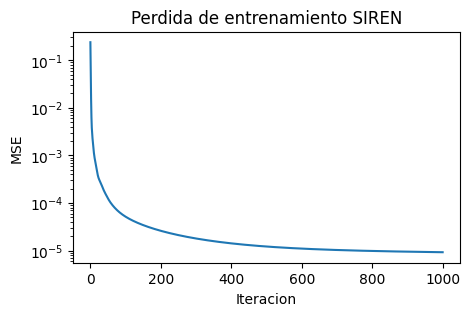

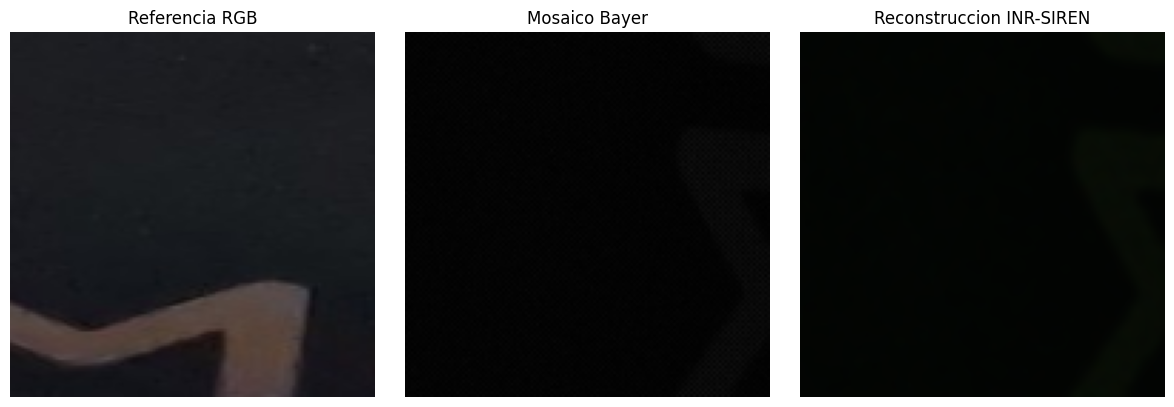

In [9]:
# Representacion neuronal implicita tipo SIREN
class SineLayer(nn.Module):
    def __init__(self, in_features, out_features, omega_0=30.0, is_first=False):
        super().__init__()
        self.omega_0 = omega_0
        self.linear = nn.Linear(in_features, out_features)
        with torch.no_grad():
            if is_first:
                self.linear.weight.uniform_(-1 / in_features, 1 / in_features)
            else:
                bound = np.sqrt(6 / in_features) / omega_0
                self.linear.weight.uniform_(-bound, bound)

    def forward(self, x):
        return torch.sin(self.omega_0 * self.linear(x))

class Siren(nn.Module):
    def __init__(self, hidden_features=256, hidden_layers=3, out_features=3):
        super().__init__()
        layers = [SineLayer(2, hidden_features, is_first=True)]
        layers += [SineLayer(hidden_features, hidden_features) for _ in range(hidden_layers)]
        layers += [nn.Linear(hidden_features, out_features)]
        self.net = nn.Sequential(*layers)

    def forward(self, coords):
        return torch.sigmoid(self.net(coords))

def build_spatial_grid(height, width):
    yy, xx = np.meshgrid(
        np.linspace(-1, 1, height, dtype=np.float32),
        np.linspace(-1, 1, width, dtype=np.float32),
        indexing="ij",
    )
    coords = np.stack([xx.ravel(), yy.ravel()], axis=1)
    return torch.from_numpy(coords).float()

def train_siren_from_mosaic(mosaic, masks, hidden_features=256, hidden_layers=3, steps=1000, learning_rate=1e-4):
    height, width = mosaic.shape
    coords = build_spatial_grid(height, width).to(DEVICE)
    mosaic_tensor = torch.from_numpy(mosaic[..., None]).float().to(DEVICE)
    masks_tensor = torch.from_numpy(masks).float().to(DEVICE)
    model = Siren(hidden_features, hidden_layers, out_features=3).to(DEVICE)
    optimizer = optim.Adam(model.parameters(), lr=learning_rate)
    history = []

    model.train()
    for step in range(steps):
        rgb_prediction = model(coords).reshape(height, width, 3)
        mosaic_prediction = torch.sum(rgb_prediction * masks_tensor, dim=-1, keepdim=True)
        loss = F.mse_loss(mosaic_prediction, mosaic_tensor)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        history.append(loss.item())

    model.eval()
    with torch.no_grad():
        reconstruction = model(coords).reshape(height, width, 3).cpu().numpy()
    return model, np.clip(reconstruction, 0.0, 1.0).astype(np.float32), history

model_inr, I_hat_inr, loss_history = train_siren_from_mosaic(
    mosaic, bayer, hidden_features=256, hidden_layers=3, steps=1000
)

plt.figure(figsize=(5, 3))
plt.plot(loss_history)
plt.yscale("log")
plt.title("Perdida de entrenamiento SIREN")
plt.xlabel("Iteracion")
plt.ylabel("MSE")
plt.show()
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
axes[0].imshow(rgb_reference)
axes[0].set_title("Referencia RGB")
axes[1].imshow(mosaic, cmap="gray", vmin=0, vmax=1)
axes[1].set_title("Mosaico Bayer")
axes[2].imshow(I_hat_inr)
axes[2].set_title("Reconstruccion INR-SIREN")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()


## 10. Red neuronal convolucional

El segundo enfoque neuronal consiste en entrenar una red convolucional que reciba como entrada la medicion mosaico y produzca directamente una imagen RGB.

La entrada se define como

$$
X_{\text{CNN}} = [Y, M_R, M_G, M_B] \in \mathbb{R}^{H \times W \times 4}.
$$

La CNN aprende una funcion

$$
g_\phi: \mathbb{R}^{H \times W \times 4} \rightarrow \mathbb{R}^{H \times W \times 3}.
$$

Primero se ajusta una version pequena sobre el par real `demo.dng`/`demo.jpg` para verificar el flujo completo con la captura de trabajo. Esta prueba mide cercania respecto al JPG de la camara y no debe interpretarse como generalizacion. La evaluacion complementaria de la CNN se realiza despues con Kodak, entrenando con varias imagenes RGB auxiliares y midiendo el desempeno sobre imagenes no vistas.


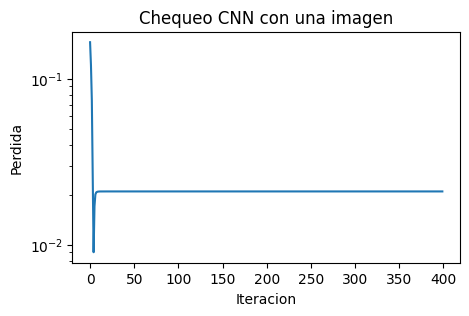

In [10]:
# Red neuronal convolucional
def build_cnn_input(mosaic, masks):
    """Construye X_CNN = [Y, M_R, M_G, M_B] con formato NCHW."""
    input_image = np.concatenate([mosaic[..., None], masks], axis=-1)
    return torch.from_numpy(input_image.transpose(2, 0, 1)[None]).float()

class ResidualBlock(nn.Module):
    def __init__(self, channels, kernel_size=3):
        super().__init__()
        padding = kernel_size // 2
        self.block = nn.Sequential(
            nn.Conv2d(channels, channels, kernel_size, padding=padding),
            nn.ReLU(inplace=True),
            nn.Conv2d(channels, channels, kernel_size, padding=padding),
        )

    def forward(self, x):
        return x + self.block(x)

class DemosaicCNN(nn.Module):
    def __init__(self, input_channels=4, hidden_channels=32, num_blocks=4):
        super().__init__()
        self.input_layer = nn.Sequential(
            nn.Conv2d(input_channels, hidden_channels, 3, padding=1),
            nn.ReLU(inplace=True),
        )
        self.residual_layers = nn.Sequential(
            *[ResidualBlock(hidden_channels) for _ in range(num_blocks)]
        )
        self.output_layer = nn.Conv2d(hidden_channels, 3, 3, padding=1)

    def forward(self, x):
        features = self.input_layer(x)
        features = self.residual_layers(features)
        return torch.sigmoid(self.output_layer(features))

def sensor_consistency_loss(prediction, input_tensor):
    """Penaliza que la reconstruccion reproduzca la medicion Bayer observada."""
    mosaic_reprojected = torch.sum(prediction * input_tensor[:, 1:4], dim=1, keepdim=True)
    return F.mse_loss(mosaic_reprojected, input_tensor[:, 0:1])

def train_cnn_single_image(model, input_tensor, target_tensor, steps=400, learning_rate=1e-3, physics_weight=0.1):
    model.train()
    optimizer = optim.Adam(model.parameters(), lr=learning_rate)
    history = []
    for step in range(steps):
        prediction = model(input_tensor)
        rgb_loss = F.mse_loss(prediction, target_tensor)
        physics_loss = sensor_consistency_loss(prediction, input_tensor)
        loss = rgb_loss + physics_weight * physics_loss
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        history.append(loss.item())
    return history

cnn_input = build_cnn_input(mosaic, bayer).to(DEVICE)
cnn_target = torch.from_numpy(rgb_reference.transpose(2, 0, 1)[None]).float().to(DEVICE)
model_cnn_single = DemosaicCNN(input_channels=4, hidden_channels=32, num_blocks=4).to(DEVICE)
cnn_single_history = train_cnn_single_image(model_cnn_single, cnn_input, cnn_target, steps=400)

model_cnn_single.eval()
with torch.no_grad():
    cnn_output = model_cnn_single(cnn_input)[0].cpu().numpy()
I_hat_cnn_single = cnn_output.transpose(1, 2, 0).astype(np.float32)

plt.figure(figsize=(5, 3))
plt.plot(cnn_single_history)
plt.yscale("log")
plt.title("Chequeo CNN con una imagen")
plt.xlabel("Iteracion")
plt.ylabel("Perdida")
plt.show()


## 10.1. Entrenamiento de la CNN con varias imagenes

El entrenamiento con una sola imagen solo verifica el pipeline. Para evaluar generalizacion se usa el dataset Kodak, siguiendo la idea del notebook `extra/cnnDemosaicing.ipynb`.

La division se hace de esta forma:

- 20 imagenes Kodak para entrenamiento.
- 4 imagenes Kodak para prueba.
- Cada imagen se divide en parches de 64 x 64.
- Los parches de prueba provienen de imagenes completas que no fueron usadas durante el entrenamiento.

Asi, cuando se reportan metricas de la CNN sobre Kodak, esas metricas corresponden a imagenes no vistas por el modelo.


Imagenes de entrenamiento: 20
Imagenes de prueba: 4
Parches de entrenamiento: 1920
Parches de prueba: 384
Epoca 01/6: perdida = 0.017733
Epoca 02/6: perdida = 0.006552
Epoca 03/6: perdida = 0.003068
Epoca 04/6: perdida = 0.002084
Epoca 05/6: perdida = 0.001523
Epoca 06/6: perdida = 0.001091
MSE promedio en parches de prueba Kodak: 0.001052


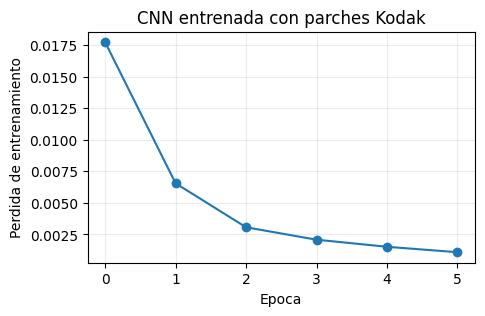

In [11]:
# Dataset Kodak para entrenamiento supervisado multi-imagen
# Rutas para ejecucion local o Colab
try:
    from google.colab import files  # noqa: F401
    IN_COLAB = True
except Exception:
    IN_COLAB = False

REPO_ROOT = Path.cwd()
if not (REPO_ROOT / "tareas" / "tarea-02").exists() and Path.cwd().name == "tarea-02":
    REPO_ROOT = Path.cwd().parents[1]

TASK_DIR = REPO_ROOT / "tareas" / "tarea-02"
LOCAL_DATASET_DIR = REPO_ROOT / "tareas" / "dataset"
DATA_DIR = Path("/content") if IN_COLAB else TASK_DIR

KODAK_DIR = DATA_DIR / "kodak"
KODAK_DIR.mkdir(exist_ok=True)
KODAK_ZIP = KODAK_DIR / "kodak.zip"
KODAK_URL = "https://arizona.box.com/shared/static/5bk6qar4vgfizmhum8onreu6sp90bz2i"

# El repositorio tambien trae tareas/dataset/01.png ... 24.png; se usa como respaldo local.
def select_local_kodak_paths(dataset_dir):
    if not dataset_dir.exists():
        return []
    selected = []
    for index in range(1, 25):
        candidates = [dataset_dir / f"{index:02d}.png", dataset_dir / f"{index}.png"]
        selected.extend([path for path in candidates if path.exists()][:1])
    return selected

local_kodak_paths = select_local_kodak_paths(LOCAL_DATASET_DIR)
if len(local_kodak_paths) >= 8:
    kodak_paths = local_kodak_paths
else:
    if not list(KODAK_DIR.rglob("kodim*.png")):
        urllib.request.urlretrieve(KODAK_URL, KODAK_ZIP)
        with zipfile.ZipFile(KODAK_ZIP, "r") as zip_ref:
            zip_ref.extractall(KODAK_DIR)
    kodak_paths = sorted(KODAK_DIR.rglob("kodim*.png"))

if len(kodak_paths) < 8:
    raise RuntimeError(f"Se encontraron {len(kodak_paths)} imagenes Kodak; revisa la descarga o tareas/dataset.")

kodak_paths = kodak_paths[:24]
train_paths = kodak_paths[:-4]
test_paths = kodak_paths[-4:]
print(f"Imagenes de entrenamiento: {len(train_paths)}")
print(f"Imagenes de prueba: {len(test_paths)}")

class KodakPatchDataset(Dataset):
    def __init__(self, image_paths, patch_size=64, stride=64, max_patches_per_image=None):
        self.samples = []
        self.patch_size = patch_size
        for path in image_paths:
            image = np.asarray(Image.open(path).convert("RGB"), dtype=np.float32) / 255.0
            height, width = image.shape[:2]
            image_samples = []
            for top in range(0, height - patch_size + 1, stride):
                for left in range(0, width - patch_size + 1, stride):
                    image_samples.append(image[top:top + patch_size, left:left + patch_size])
            if max_patches_per_image is not None:
                image_samples = image_samples[:max_patches_per_image]
            self.samples.extend(image_samples)

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, index):
        rgb = self.samples[index]
        masks = bayer_masks(self.patch_size, self.patch_size, pattern=bayer_pattern)
        mosaic_patch = make_bayer_mosaic(rgb, masks)
        input_patch = np.concatenate([mosaic_patch[..., None], masks], axis=-1)
        input_tensor = torch.from_numpy(input_patch.transpose(2, 0, 1)).float()
        target_tensor = torch.from_numpy(rgb.transpose(2, 0, 1)).float()
        return input_tensor, target_tensor

train_dataset = KodakPatchDataset(train_paths, patch_size=64, stride=64)
test_dataset = KodakPatchDataset(test_paths, patch_size=64, stride=64)
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, num_workers=0)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False, num_workers=0)
print(f"Parches de entrenamiento: {len(train_dataset)}")
print(f"Parches de prueba: {len(test_dataset)}")

def train_cnn_loader(model, loader, epochs=6, learning_rate=1e-3, physics_weight=0.1):
    model.train()
    optimizer = optim.Adam(model.parameters(), lr=learning_rate)
    history = []
    for epoch in range(epochs):
        epoch_loss = 0.0
        for inputs, targets in loader:
            inputs = inputs.to(DEVICE)
            targets = targets.to(DEVICE)
            predictions = model(inputs)
            rgb_loss = F.mse_loss(predictions, targets)
            physics_loss = sensor_consistency_loss(predictions, inputs)
            loss = rgb_loss + physics_weight * physics_loss
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            epoch_loss += loss.item() * inputs.size(0)
        epoch_loss /= len(loader.dataset)
        history.append(epoch_loss)
        print(f"Epoca {epoch + 1:02d}/{epochs}: perdida = {epoch_loss:.6f}")
    return history

def evaluate_cnn_loader(model, loader):
    model.eval()
    losses = []
    with torch.no_grad():
        for inputs, targets in loader:
            predictions = model(inputs.to(DEVICE)).cpu()
            losses.append(F.mse_loss(predictions, targets).item())
    return float(np.mean(losses))

model_cnn_kodak = DemosaicCNN(input_channels=4, hidden_channels=32, num_blocks=4).to(DEVICE)
kodak_loss_history = train_cnn_loader(model_cnn_kodak, train_loader, epochs=6)
kodak_test_mse = evaluate_cnn_loader(model_cnn_kodak, test_loader)
print(f"MSE promedio en parches de prueba Kodak: {kodak_test_mse:.6f}")

plt.figure(figsize=(5, 3))
plt.plot(kodak_loss_history, marker="o")
plt.xlabel("Epoca")
plt.ylabel("Perdida de entrenamiento")
plt.title("CNN entrenada con parches Kodak")
plt.grid(alpha=0.25)
plt.show()


## 11. Variantes experimentales

Para estudiar el efecto de la arquitectura se comparan dos CNN entrenadas sobre Kodak:

| Metodo | Canales ocultos | Bloques residuales | Uso |
|---|---:|---:|---|
| CNN pequena | 16 | 2 | Menor costo computacional |
| CNN base | 32 | 4 | Mayor capacidad de reconstruccion |

La comparacion se reporta sobre el conjunto de prueba, es decir, sobre parches provenientes de imagenes no vistas durante entrenamiento.


In [12]:
# Variantes de arquitectura y entrenamiento para la CNN Kodak
cnn_experiments = [
    {"nombre": "CNN pequena", "hidden_channels": 16, "num_blocks": 2, "epochs": 4},
    {"nombre": "CNN base", "hidden_channels": 32, "num_blocks": 4, "epochs": 4},
]

def run_cnn_experiment(config):
    start_time = time.perf_counter()
    model = DemosaicCNN(
        input_channels=4,
        hidden_channels=config["hidden_channels"],
        num_blocks=config["num_blocks"],
    ).to(DEVICE)
    history = train_cnn_loader(model, train_loader, epochs=config["epochs"], physics_weight=0.1)
    test_mse = evaluate_cnn_loader(model, test_loader)
    return {
        "metodo": config["nombre"],
        "canales": config["hidden_channels"],
        "bloques": config["num_blocks"],
        "epocas": config["epochs"],
        "MSE prueba": test_mse,
        "tiempo [s]": time.perf_counter() - start_time,
    }, history

variant_rows = []
variant_histories = {}
for config in cnn_experiments:
    row, history = run_cnn_experiment(config)
    variant_rows.append(row)
    variant_histories[config["nombre"]] = history

variants_df = pd.DataFrame(variant_rows).sort_values("MSE prueba")
display(variants_df.round(4))


Epoca 01/4: perdida = 0.024378
Epoca 02/4: perdida = 0.008728
Epoca 03/4: perdida = 0.007482
Epoca 04/4: perdida = 0.006483
Epoca 01/4: perdida = 0.014129
Epoca 02/4: perdida = 0.005914
Epoca 03/4: perdida = 0.002759
Epoca 04/4: perdida = 0.001823


,metodo,canales,bloques,epocas,MSE prueba,tiempo [s]
1,CNN base,32,4,4,0.0016,8.2131
0,CNN pequena,16,2,4,0.0076,3.5397


## 12. Metricas de evaluacion

Para comparar las reconstrucciones se usaran metricas entre la imagen de referencia $I_{\text{ref}}$ y cada estimacion $\hat{I}$.

### Error cuadratico medio

$$
\operatorname{MSE}(I, \hat{I}) = \frac{1}{3HW}\sum_{i=1}^{H}\sum_{j=1}^{W}\sum_{c=1}^{3}
\left(I_c(i,j) - \hat{I}_c(i,j)\right)^2.
$$

### PSNR

$$
\operatorname{PSNR}(I, \hat{I}) = 10 \log_{10}\left(\frac{\operatorname{MAX}_I^2}{\operatorname{MSE}(I, \hat{I})}\right).
$$

Si las imagenes estan normalizadas en $[0,1]$, entonces $\operatorname{MAX}_I = 1$.

### SSIM

El indice SSIM mide similitud estructural considerando luminancia, contraste y estructura. Se usara como complemento al PSNR, ya que este ultimo no siempre refleja adecuadamente la calidad visual percibida.


In [13]:
# Metricas de calidad
def compute_metrics(reference, estimate):
    reference = np.clip(reference.astype(np.float32), 0.0, 1.0)
    estimate = np.clip(estimate.astype(np.float32), 0.0, 1.0)
    mse = float(np.mean((reference - estimate) ** 2))
    psnr = float(peak_signal_noise_ratio(reference, estimate, data_range=1.0))
    ssim_value = float(ssim(reference, estimate, channel_axis=-1, data_range=1.0))
    return {"MSE": mse, "PSNR [dB]": psnr, "SSIM": ssim_value}

def evaluate_loader_metrics(model, loader):
    rows = []
    model.eval()
    with torch.no_grad():
        for inputs, targets in loader:
            predictions = model(inputs.to(DEVICE)).cpu().numpy().transpose(0, 2, 3, 1)
            targets = targets.numpy().transpose(0, 2, 3, 1)
            for target, prediction in zip(targets, predictions):
                rows.append(compute_metrics(target, prediction))
    return pd.DataFrame(rows).mean(numeric_only=True).to_dict()

dng_results_df = pd.DataFrame([
    {"experimento": "DNG/JPG", "metodo": "Bilineal", **compute_metrics(rgb_reference, I_hat_classic)},
    {"experimento": "DNG/JPG", "metodo": "INR-SIREN", **compute_metrics(rgb_reference, I_hat_inr)},
    {"experimento": "DNG/JPG", "metodo": "CNN una imagen", **compute_metrics(rgb_reference, I_hat_cnn_single)},
])

kodak_test_metrics = evaluate_loader_metrics(model_cnn_kodak, test_loader)
kodak_results_df = pd.DataFrame([
    {"experimento": "Kodak prueba", "metodo": "CNN multi-imagen", **kodak_test_metrics}
])

display(dng_results_df.round(4))
display(kodak_results_df.round(4))


,experimento,metodo,MSE,PSNR [dB],SSIM
0,DNG/JPG,Bilineal,0.0171,17.6767,0.2459
1,DNG/JPG,INR-SIREN,0.0170,17.7017,0.2523
2,DNG/JPG,CNN una imagen,0.0209,16.7993,0.0069


,experimento,metodo,MSE,PSNR [dB],SSIM
0,Kodak prueba,CNN multi-imagen,0.0011,30.9366,0.9299


## 13. Visualizacion de resultados

La comparacion visual principal se realiza sobre la captura real. La grilla incluye:

1. JPG procesado por la camara.
2. Medicion mosaico leida desde el DNG.
3. Reconstruccion clasica bilineal.
4. Reconstruccion con representacion implicita.
5. Reconstruccion con CNN ajustada al par DNG/JPG.
6. Mapas de diferencia absoluta contra el JPG.

El error absoluto por pixel se define como

$$
E(i,j) =
rac{1}{3}\sum_{c=1}^{3}\left|I_{	ext{JPG},c}(i,j)-\hat{I}_c(i,j)
ight|.
$$


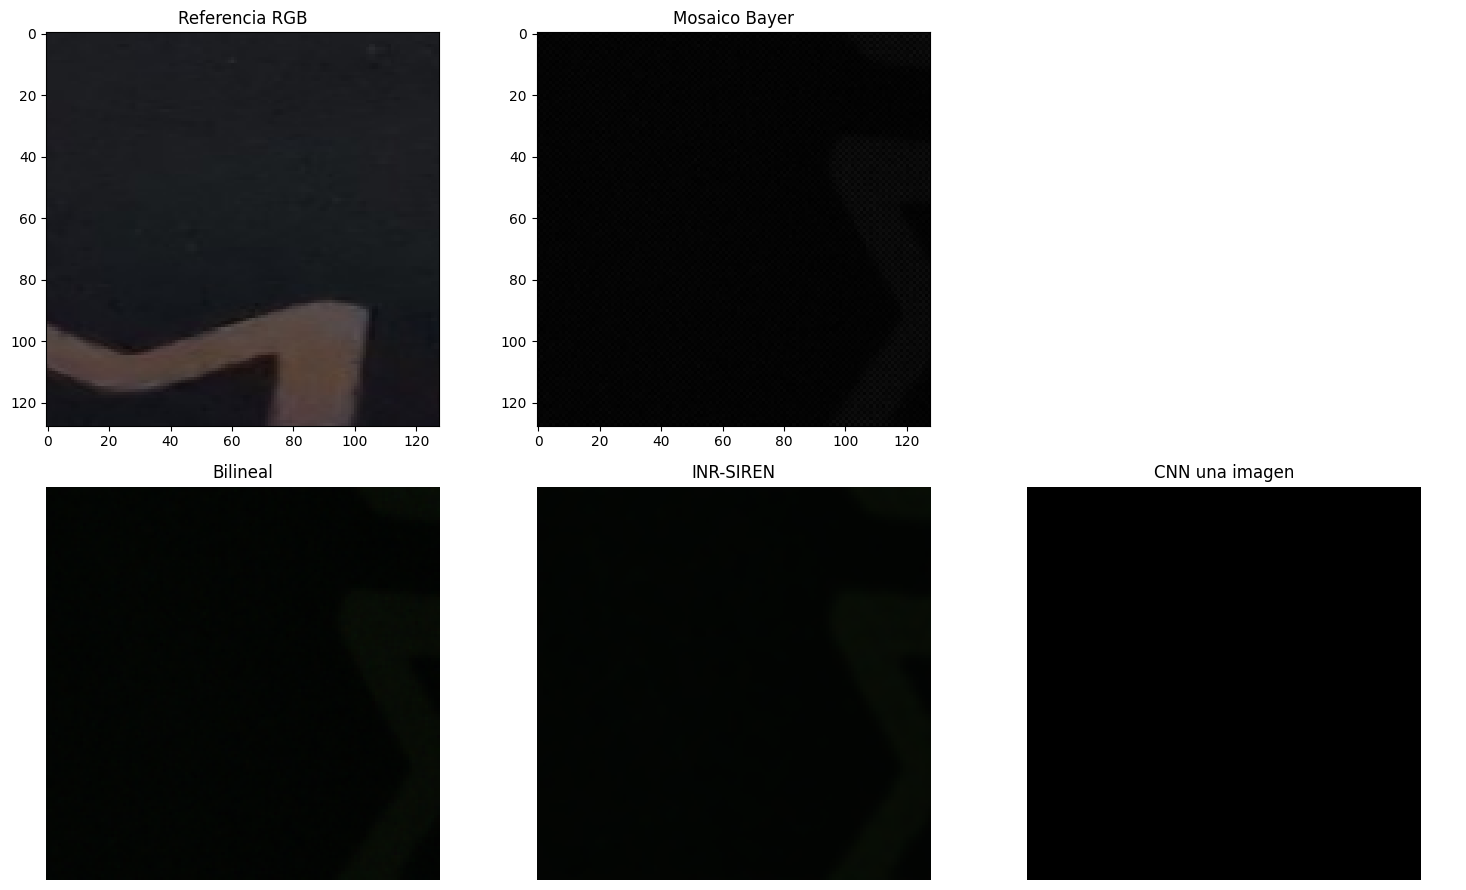

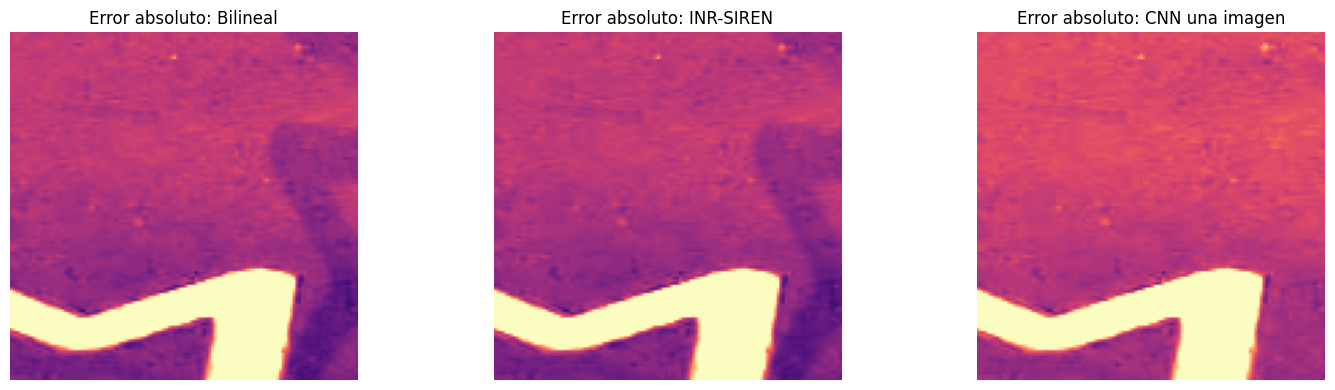

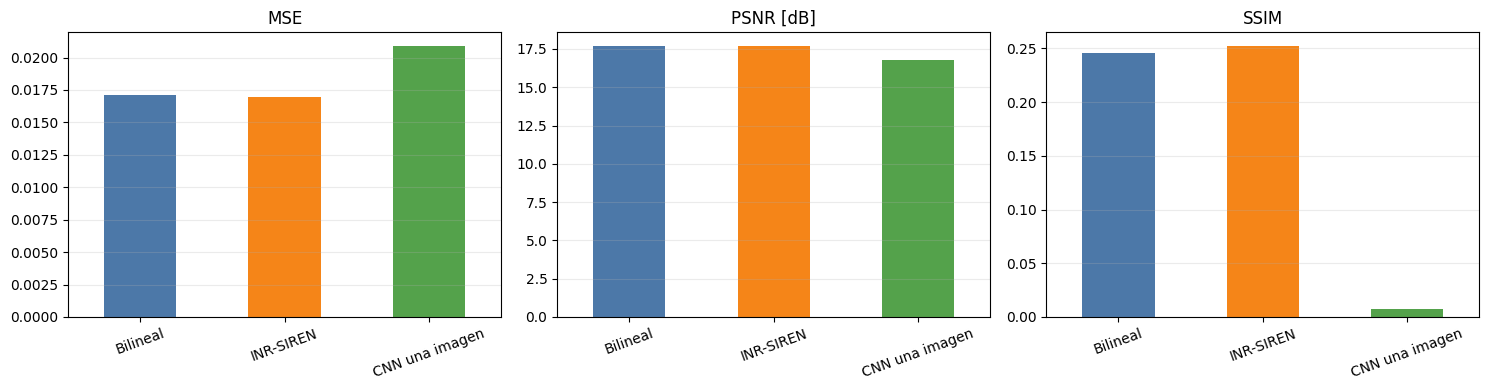

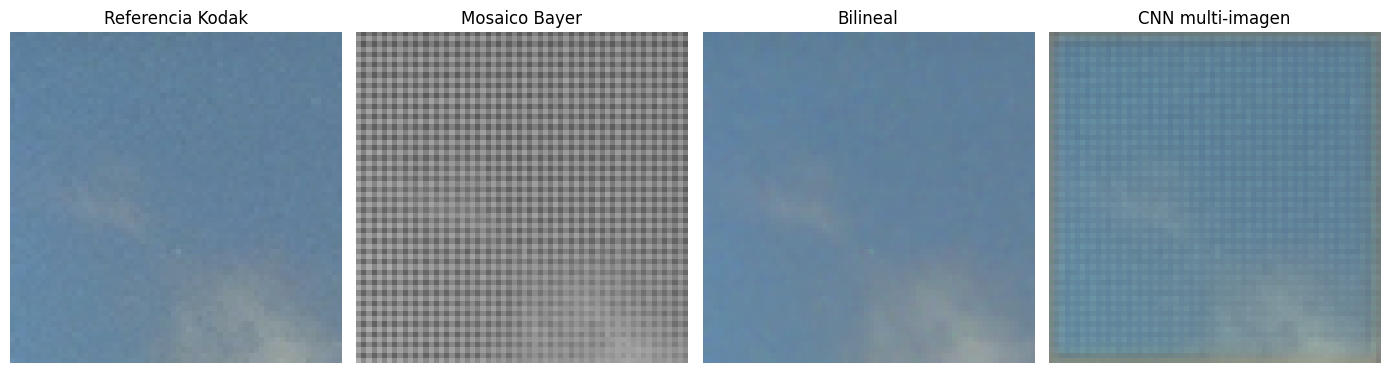

In [14]:
# Visualizacion comparativa
def show_comparison(reference, mosaic, reconstructions, error_scale=5):
    methods = list(reconstructions.keys())
    fig, axes = plt.subplots(2, 3, figsize=(15, 9))

    axes[0, 0].imshow(reference)
    axes[0, 0].set_title("Referencia RGB")
    axes[0, 1].imshow(mosaic, cmap="gray", vmin=0, vmax=1)
    axes[0, 1].set_title("Mosaico Bayer")
    axes[0, 2].axis("off")

    for ax, (method, reconstruction) in zip(axes[1], reconstructions.items()):
        ax.imshow(np.clip(reconstruction, 0, 1))
        ax.set_title(method)
        ax.axis("off")

    plt.tight_layout()
    plt.show()

    fig, axes = plt.subplots(1, len(methods), figsize=(5 * len(methods), 4))
    if len(methods) == 1:
        axes = [axes]
    for ax, (method, reconstruction) in zip(axes, reconstructions.items()):
        error = np.mean(np.abs(reference - reconstruction), axis=-1)
        ax.imshow(np.clip(error * error_scale, 0, 1), cmap="magma", vmin=0, vmax=1)
        ax.set_title(f"Error absoluto: {method}")
        ax.axis("off")
    plt.tight_layout()
    plt.show()

dng_reconstructions = {
    "Bilineal": I_hat_classic,
    "INR-SIREN": I_hat_inr,
    "CNN una imagen": I_hat_cnn_single,
}
show_comparison(rgb_reference, mosaic, dng_reconstructions)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
colors = ["#4C78A8", "#F58518", "#54A24B"]
for ax, metric in zip(axes, ["MSE", "PSNR [dB]", "SSIM"]):
    dng_results_df.plot(kind="bar", x="metodo", y=metric, ax=ax, color=colors, legend=False)
    ax.set_title(metric)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=20)
    ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

# Ejemplo de generalizacion sobre un parche Kodak no usado en entrenamiento.
if "model_cnn_kodak" in globals() and len(test_dataset) > 0:
    test_input, test_target = test_dataset[0]
    with torch.no_grad():
        test_prediction = model_cnn_kodak(test_input[None].to(DEVICE))[0].cpu().numpy()
    test_reference = test_target.numpy().transpose(1, 2, 0)
    test_mosaic = test_input[0].numpy()
    test_reconstruction = test_prediction.transpose(1, 2, 0)
    test_bilinear = demosaic_bilinear(test_mosaic, bayer_masks(*test_mosaic.shape, pattern=bayer_pattern))

    fig, axes = plt.subplots(1, 4, figsize=(14, 4))
    axes[0].imshow(test_reference)
    axes[0].set_title("Referencia Kodak")
    axes[1].imshow(test_mosaic, cmap="gray", vmin=0, vmax=1)
    axes[1].set_title("Mosaico Bayer")
    axes[2].imshow(test_bilinear)
    axes[2].set_title("Bilineal")
    axes[3].imshow(np.clip(test_reconstruction, 0, 1))
    axes[3].set_title("CNN multi-imagen")
    for ax in axes:
        ax.axis("off")
    plt.tight_layout()
    plt.show()


## 14. Analisis

En el experimento principal con `demo.dng` y `demo.jpg`, la interpolacion bilineal permite obtener una reconstruccion RGB directamente desde la medicion real del sensor. Sin embargo, la comparacion con el JPG de la camara debe leerse con cuidado: la camara no solo hizo demosaicking, tambien aplico balance de blancos, correccion de color, nitidez, reduccion de ruido, compresion y mapeo tonal. Por eso las diferencias visuales no corresponden exclusivamente al algoritmo de interpolacion.

La representacion implicita INR-SIREN ajusta una funcion continua usando solo las muestras observadas del mosaico DNG. Su ventaja es que no necesita un dataset externo para producir una reconstruccion de la captura real. Su limitacion es que se optimiza para una sola imagen y puede suavizar detalles finos o introducir diferencias cromaticas respecto al JPG procesado.

La CNN ajustada con el par `demo.dng`/`demo.jpg` aprende una transformacion supervisada hacia la apariencia del JPG. Esto puede mejorar las metricas frente a la referencia de camara, pero no demuestra generalizacion por si solo. Por esa razon se mantiene el experimento Kodak como evaluacion complementaria: permite entrenar y probar la CNN en imagenes distintas, aunque esos mosaicos sean sinteticos.

En conjunto, el notebook queda centrado en una captura real RAW/DNG y usa Kodak solo como apoyo para estudiar generalizacion de la red convolucional.


## 15. Conclusiones

Se completo un flujo de demosaicking centrado en una captura real: el notebook descarga `demo.dng` y `demo.jpg`, lee la medicion RAW del sensor, detecta el patron CFA/Bayer desde los metadatos y construye las mascaras necesarias para entrenar o aplicar metodos de reconstruccion.

El metodo bilineal funciona como linea base clasica y reconstruye una imagen RGB a partir del mosaico real. La INR-SIREN permite ajustar una representacion neuronal por imagen usando la consistencia con las muestras observadas. La CNN permite aprender una reconstruccion supervisada hacia el JPG procesado por la camara, aunque sus resultados sobre una sola captura deben interpretarse como ajuste al ejemplo y no como evidencia de generalizacion.

La principal diferencia respecto a un experimento sintetico es que el JPG no es una verdad de terreno perfecta: es una salida procesada por el pipeline de la camara. Aun asi, usar el par DNG/JPG permite conectar el modelo Bayer teorico con datos reales y observar de forma practica las diferencias entre una medicion RAW, un revelado basico y una imagen final de camara.
